# Figure S1a
Temperature $\theta_v$ of each vertex of the Charles River basin. Each line is one reach of the river from the HydroRIVERS database. The orange circle marks the vertex at the mouth of the river.

In [1]:
import json

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Circle

from fixloc import style as S

d = json.load(open('data.json'))

In [2]:
# Text style of the published figure: Times New Roman with STIX math, tick labels in DejaVu Sans, no LaTeX.
matplotlib.rcdefaults()
plt.rcParams.update({
  'font.family': 'serif',
  'font.serif': ['Times New Roman', 'STIXGeneral'],
  'mathtext.fontset': 'stix',
  'ytick.major.width': 0.6,
})
TICK = 'DejaVu Sans'
INK, ORANGE = '#2b2b2b', '#eb6834'
SEQ = LinearSegmentedColormap.from_list('blue', ['#ffffff', '#9ec5f4', '#3987e5', '#1c5cab', '#0d366b'])


def draw(ax, vals, vmax):
  '''Each reach as its polyline over a dark outline, colored by vals, wider for a higher stream order.

  The orange circle marks the vertex at the mouth of the river.'''
  for xy, order, x in zip(d['lines'], d['order'], vals):
    xy = np.array(xy)
    lw = 0.9 + 0.55 * order
    ax.plot(xy[:, 0], xy[:, 1], color=SEQ(min(float(x), vmax) / vmax), lw=lw, solid_capstyle='round', zorder=2)
    ax.plot(xy[:, 0], xy[:, 1], color=INK, lw=lw + 0.5, solid_capstyle='round', zorder=1)
  mx, my = d['mouth']
  ax.add_patch(Circle((mx, my), 0.012, facecolor='none', edgecolor=ORANGE, lw=1.6, zorder=5))
  ax.set_aspect(1 / np.cos(np.radians(my)))
  ax.set_axis_off()
  ax.margins(0.04)

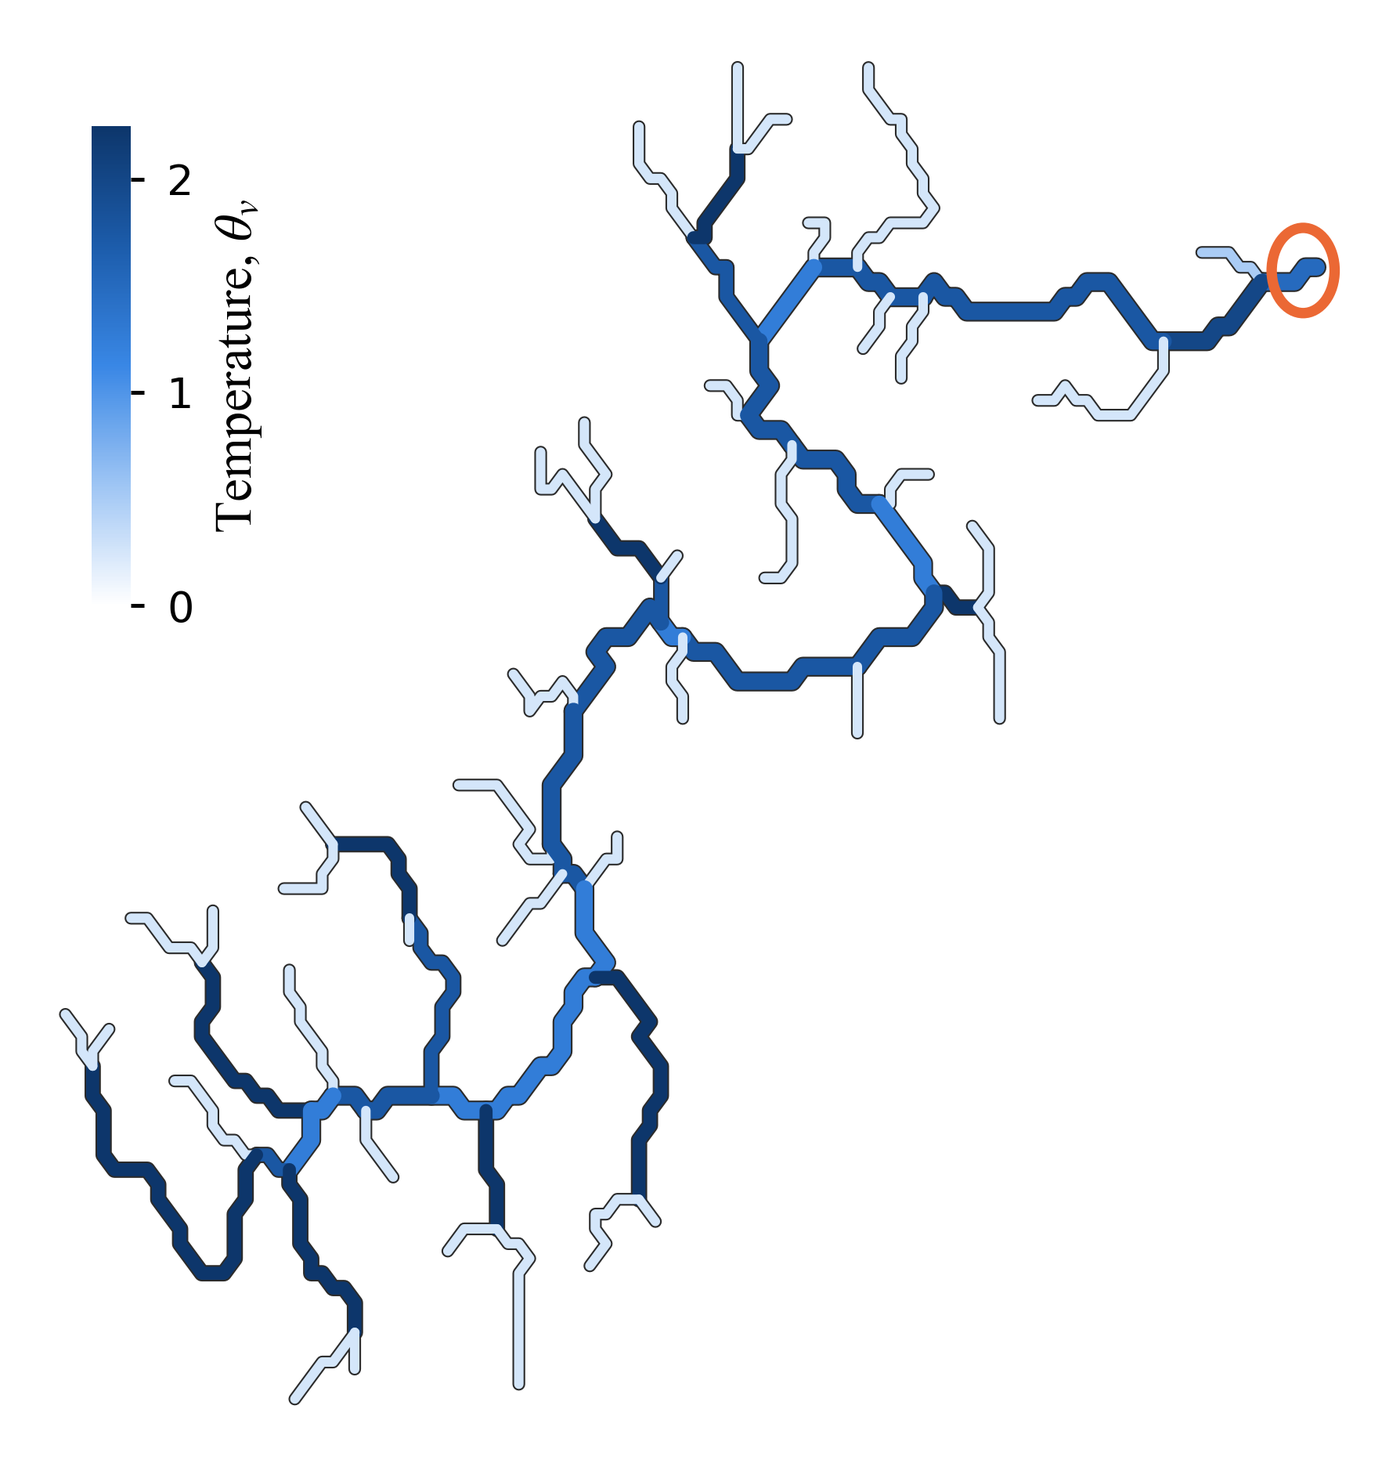

In [3]:
fig = plt.figure(figsize=(7.0, 3.4))
left = 0.01
ax = fig.add_axes([left, 0.02, 0.47, 0.9])
draw(ax, d['theta'], 2.25)
cax = fig.add_axes([left + 0.05, 0.55, 0.012, 0.3])
cb = fig.colorbar(plt.cm.ScalarMappable(cmap=SEQ, norm=plt.Normalize(0, 2.25)), cax=cax)
cb.outline.set_visible(False)
cb.set_ticks([0, 1, 2])
cb.ax.tick_params(labelsize=6.5, length=2, labelfontfamily=TICK)
cb.set_label(r'Temperature, $\theta_v$', fontsize=8, labelpad=3)
S.save_panel(fig, 'a')